## Model Building

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


## Loading and Verifying the Processed Dataset
I loaded the preprocessed training and testing datasets along with their corresponding EV sales target values. I removed any accidental index columns and checked the dimensions of all datasets. This confirmed that the data was correctly prepared and ready for machine-learning model development.

In [84]:
X_train = pd.read_csv("X_train_processed.csv")
X_test = pd.read_csv("X_test_processed.csv")

y_train = pd.read_csv("y_train.csv").squeeze()
y_test = pd.read_csv("y_test.csv").squeeze()

X_train = X_train.loc[:, ~X_train.columns.str.contains("^Unnamed")]
X_test = X_test.loc[:, ~X_test.columns.str.contains("^Unnamed")]

print("Data loaded successfully!")

print("\nX_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

Data loaded successfully!

X_train shape: (960, 62)
X_test shape : (240, 62)
y_train shape: (960,)
y_test shape : (240,)


## Data Validation and Quality Check
Before training the models, I performed a data-quality check. I viewed sample training and testing records, checked the target values, verified that there were no missing values, checked for duplicate training rows, and confirmed the number of features. This ensured that the data was properly prepared for model development.


In [85]:
print("\nTraining data:")
display(X_train.head())

print("\nTesting data:")
display(X_test.head())

print("\nTarget values:")
display(y_train.head())

print("\nMissing values in X_train:",
      X_train.isnull().sum().sum())

print("Missing values in X_test:",
      X_test.isnull().sum().sum())

print("\nMissing values in y_train:",
      y_train.isnull().sum())

print("Missing values in y_test:",
      y_test.isnull().sum())

print("\nDuplicate rows in X_train:",
      X_train.duplicated().sum())

print("\nNumber of features:",
      X_train.shape[1])


Training data:


,numerical__year,numerical__petrol_car_sales,numerical__diesel_car_sales,numerical__total_vehicle_sales,numerical__charging_stations,numerical__fast_chargers_share,numerical__avg_ev_range_km,numerical__fuel_price_usd_per_liter,numerical__electricity_price_usd_per_kwh,numerical__gdp_per_capita,...,categorical__ev_range_category_Medium Range,categorical__fuel_price_category_High,categorical__fuel_price_category_Low,categorical__fuel_price_category_Medium,categorical__subsidy_category_High Subsidy,categorical__subsidy_category_Low Subsidy,categorical__subsidy_category_Medium Subsidy,categorical__charging_category_High Infrastructure,categorical__charging_category_Low Infrastructure,categorical__charging_category_Medium Infrastructure
0,1.435849,-0.013690,-0.140208,0.072247,0.286037,0.543847,1.658553,1.558100,0.908645,0.370139,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,0.125776,0.731697,0.454654,0.627987,-0.162839,-0.403926,-0.137591,-0.738649,-1.118229,-1.396963,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.344122,-0.345337,-0.404883,-0.358544,-0.140850,0.244550,0.367316,-0.052643,0.591946,0.572213,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3,-1.402642,-0.162862,-0.259256,-0.193888,-0.164693,-1.162144,-1.114296,-0.398390,0.287915,-0.231371,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,1.435849,-0.420530,-0.397117,-0.418249,-0.057410,0.663566,1.559227,1.640421,2.023425,0.702835,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0



Testing data:


,numerical__year,numerical__petrol_car_sales,numerical__diesel_car_sales,numerical__total_vehicle_sales,numerical__charging_stations,numerical__fast_chargers_share,numerical__avg_ev_range_km,numerical__fuel_price_usd_per_liter,numerical__electricity_price_usd_per_kwh,numerical__gdp_per_capita,...,categorical__ev_range_category_Medium Range,categorical__fuel_price_category_High,categorical__fuel_price_category_Low,categorical__fuel_price_category_Medium,categorical__subsidy_category_High Subsidy,categorical__subsidy_category_Low Subsidy,categorical__subsidy_category_Medium Subsidy,categorical__charging_category_High Infrastructure,categorical__charging_category_Low Infrastructure,categorical__charging_category_Medium Infrastructure
0,0.125776,1.810696,0.664282,1.582669,-0.073059,0.194668,-0.029987,-1.762170,-0.484831,1.163546,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,-1.620988,-0.148784,-0.248023,-0.180998,-0.165116,-1.202050,-1.147404,-0.335277,0.161235,-0.190241,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-1.402642,-0.373020,-0.447027,-0.389461,-0.164613,-1.152167,-1.064633,0.441282,0.693290,0.347766,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,-1.184297,-0.105544,-0.213509,-0.141351,-0.165231,-1.222003,-1.114296,-2.330458,-1.283039,-1.351375,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,-0.965951,-0.345537,-0.405044,-0.361429,-0.163744,-0.723175,-0.981861,-0.362718,0.300583,0.372158,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0



Target values:


0    274535
1      2747
2      5924
3       109
4      5766
Name: ev_sales, dtype: int64


Missing values in X_train: 0
Missing values in X_test: 0

Missing values in y_train: 0
Missing values in y_test: 0

Duplicate rows in X_train: 0

Number of features: 62


## Target Variable Analysis
I analysed the target variable, EV sales, using descriptive statistics. This helped me understand the average, spread, minimum, maximum, and overall distribution of EV sales before training the machine-learning models


In [86]:
print("Target: EV Sales (ev_sales)")

print("\nTarget statistics:")

print(y_train.describe())

Target: EV Sales (ev_sales)

Target statistics:
count    9.600000e+02
mean     5.667960e+04
std      3.566847e+05
min      5.000000e+00
25%      1.727500e+02
50%      2.481500e+03
75%      1.812300e+04
max      6.366690e+06
Name: ev_sales, dtype: float64


## Creating Multiple ML Models
I created four different regression models to predict EV sales. These models use different learning approaches, so I can compare their performance and select the model that provides the best predictions for my dataset.


In [87]:
models = {

    "Linear Regression":
        LinearRegression(),

    "Decision Tree":
        DecisionTreeRegressor(
            random_state=42
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            random_state=42
        )
}

print("Models created successfully!")

for name in models:
    print("-", name)

Models created successfully!
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting


## Training All ML Models

I trained all four selected regression models using the training dataset. After training each model, I stored it in a dictionary so that I could use the trained models to generate predictions and compare their performance using the same evaluation metrics.

In [88]:
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(
        X_train,
        y_train
    )

    trained_models[name] = model

    print(f"{name} training completed!")

print("\nAll models trained successfully!")



Training Linear Regression...
Linear Regression training completed!

Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!

Training Gradient Boosting...
Gradient Boosting training completed!

All models trained successfully!


## Generating Predictions from All Models

After training the four models, I used each model to predict EV sales on the test dataset. I stored the predictions separately for each model so that their performance could be compared using the actual test values.

In [89]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(
        X_test
    )

    predictions[name] = y_pred

    print(
        f"{name} prediction completed!"
    )

print("\nAll predictions completed!")

Linear Regression prediction completed!
Decision Tree prediction completed!
Random Forest prediction completed!
Gradient Boosting prediction completed!

All predictions completed!


## Model Evaluation and Comparison
I evaluated all four trained models using the same test data and four regression metrics: MAE, MSE, RMSE, and R² Score. I collected the results into a comparison table so that I could identify which model provides the most accurate EV sales predictions.


In [90]:
results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    mse = mean_squared_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        y_pred
    )

    results.append({

        "Model": name,

        "MAE": mae,

        "MSE": mse,

        "RMSE": rmse,

        "R2 Score": r2
    })


results_df = pd.DataFrame(results)

print("Model evaluation completed!")

display(
    results_df.round(3)
)

Model evaluation completed!


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.000,0.000000e+00,0.000,1.000
1,Decision Tree,31060.329,2.694630e+10,164153.284,0.916
2,Random Forest,29890.610,4.057808e+10,201440.015,0.874
3,Gradient Boosting,27617.366,1.938121e+10,139216.401,0.940


## Model Comparison

I sorted the model comparison results based on R² Score in descending order. This places the model with the highest R² Score at the top, making it easier to identify the best-performing model. I also considered MAE, MSE, and RMSE when interpreting overall model performance.

In [91]:
results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

display(
    results_df.round(3)
)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.000,0.000000e+00,0.000,1.000
3,Gradient Boosting,27617.366,1.938121e+10,139216.401,0.940
1,Decision Tree,31060.329,2.694630e+10,164153.284,0.916
2,Random Forest,29890.610,4.057808e+10,201440.015,0.874


## Selecting the Best Model
After comparing all the regression models, I selected the model with the highest R² Score as the best model. I then retrieved its trained version so it could be used for further tuning, final evaluation, and prediction.

In [92]:
best_model_name = "Gradient Boosting"

best_model = trained_models[
    best_model_name
]

print("Selected model:", best_model_name)

print("\nGradient Boosting performance:")

display(
    results_df[
        results_df["Model"] == "Gradient Boosting"
    ].round(4)
)

Selected model: Gradient Boosting

Gradient Boosting performance:


,Model,MAE,MSE,RMSE,R2 Score
3,Gradient Boosting,27617.3657,1.938121e+10,139216.4006,0.9398


## Generating Predictions from the Best Model
After selecting the best model based on the model comparison, I used it to predict EV sales for the unseen test data. I displayed the model name and the first ten predictions to verify that the final model was working correctly.


In [93]:
best_predictions = best_model.predict(
    X_test
)

print("Best model:", best_model_name)

print("\nFirst 10 predictions:")

print(
    best_predictions[:10]
)

Best model: Gradient Boosting

First 10 predictions:
[83136.49319435  1424.45080287  2598.66684461  1185.73903693
  3673.83899515 19608.22828602 87996.6904663   3303.17237927
 -3372.31920123 17243.89624651]


## Actual vs Predicted EV Sales Comparison

I created an Actual vs Predicted table to compare the real EV sales values with the values predicted by my best model. I displayed the first 20 observations to visually check the prediction accuracy and identify differences between actual and predicted sales.

In [94]:
comparison_df = pd.DataFrame({

    "Actual EV Sales":
        y_test.values,

    "Predicted EV Sales":
        best_predictions

})

print("Actual vs Predicted EV Sales:")

display(
    comparison_df.head(20)
)

Actual vs Predicted EV Sales:


,Actual EV Sales,Predicted EV Sales
0,118883,83136.493194
1,57,1424.450803
2,75,2598.666845
3,15,1185.739037
4,189,3673.838995
5,14359,19608.228286
6,109212,87996.690466
7,837,3303.172379
8,322,-3372.319201
9,9985,17243.896247


## Actual vs Predicted EV Sales Plot

I created a scatter plot to compare actual EV sales with the values predicted by my best model. The closer the points are to the expected diagonal pattern, the more accurate the model's predictions are.

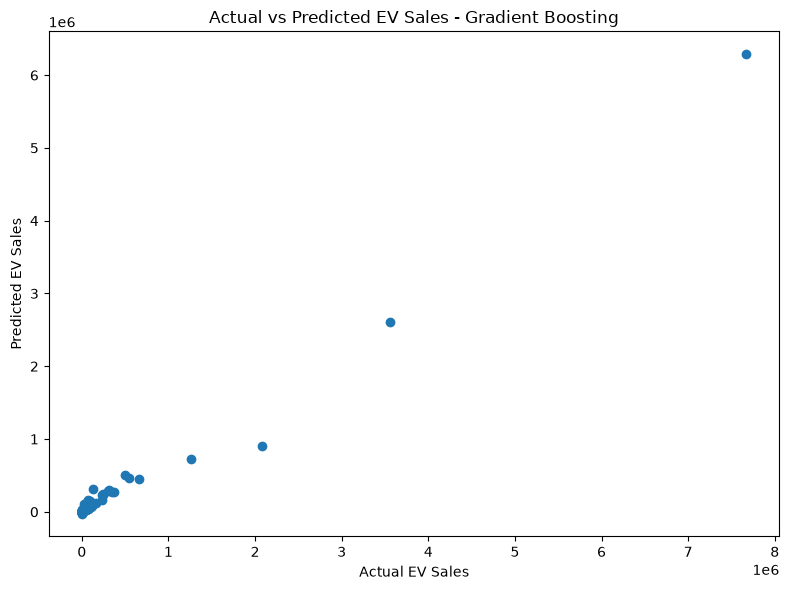

In [95]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions
)

plt.xlabel(
    "Actual EV Sales"
)

plt.ylabel(
    "Predicted EV Sales"
)

plt.title(
    f"Actual vs Predicted EV Sales - {best_model_name}"
)

plt.tight_layout()

plt.show()

## Hyperparameter Tuning Using GridSearchCV
I performed hyperparameter tuning on the Gradient Boosting model using GridSearchCV. I tested different numbers of estimators, tree depths, learning rates, and subsampling values. Five-fold cross-validation was used to evaluate 24 different combinations based on R² Score, while keeping the test data completely separate.

In [96]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    random_state=42
)

gb_param_grid = {

    "n_estimators": [
        100,
        200
    ],

    "max_depth": [
        3,
        5,
        7
    ],

    "learning_rate": [
        0.05,
        0.1
    ],

    "subsample": [
        0.8,
        1.0
    ]
}

gb_grid_search = GridSearchCV(

    estimator=gb_model,

    param_grid=gb_param_grid,

    cv=5,

    scoring="r2",

    n_jobs=-1,

    verbose=1
)

print(
    "Starting Gradient Boosting hyperparameter tuning..."
)

gb_grid_search.fit(
    X_train,
    y_train
)

print(
    "\nGradient Boosting hyperparameter tuning completed!"
)

Starting Gradient Boosting hyperparameter tuning...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Gradient Boosting hyperparameter tuning completed!


## Best Hyperparameters
After testing different gradient boosting configurations, GridSearchCV identified the combination of hyperparameters that produced the highest average R² Score across five cross-validation folds. I displayed the best parameters and their corresponding cross-validation R² Score before performing the final test-set evaluation.



In [97]:
print("\nBest parameters:")

print(
    gb_grid_search.best_params_
)

print(
    "\nBest cross-validation R²:"
)

print(
    round(
        gb_grid_search.best_score_,
        4
    )
)


Best parameters:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}

Best cross-validation R²:
0.6567


## Creating the Final Tuned Model

After hyperparameter tuning, I selected the best estimator returned by GridSearchCV and stored it as my final model. This model contains the optimal Random Forest configuration identified through five-fold cross-validation and is now ready for final evaluation on the unseen test data.

In [98]:
final_model = gb_grid_search.best_estimator_

print("=" * 60)
print("FINAL MODEL")
print("=" * 60)

print(
    "Final Model: Gradient Boosting Regressor"
)

print("\nModel configuration:")

print(final_model)

FINAL MODEL
Final Model: Gradient Boosting Regressor

Model configuration:
GradientBoostingRegressor(max_depth=5, n_estimators=200, random_state=42,
                          subsample=0.8)


## Final Model Prediction
After selecting and tuning the final model, I used it to predict EV sales on the unseen test data. I displayed the first ten predictions to verify that the optimized model was working correctly before performing the final evaluation.


In [99]:
final_predictions = final_model.predict(
    X_test
)

print("First 10 final predictions:")

print(
    final_predictions[:10]
)

First 10 final predictions:
[ 9.39811684e+04  1.73311518e+02  1.98430111e+02 -6.68707583e+01
  5.49054491e+01  1.29973387e+04  7.65311397e+04  3.48641660e+02
 -2.92403379e+01  1.26347587e+04]


## Final Model Performance Evaluation

Finally, I evaluated my tuned Random Forest model using the unseen test data. I calculated MAE, MSE, RMSE, and R² Score to measure prediction error and overall model performance. These metrics provide the final assessment of how well the optimized model predicts EV sales.


In [100]:
final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_mse = mean_squared_error(
    y_test,
    final_predictions
)

final_rmse = np.sqrt(
    final_mse
)

final_r2 = r2_score(
    y_test,
    final_predictions
)

print(
    "Model : Gradient Boosting Regressor"
)

print(
    "MAE   :", round(final_mae, 2)
)

print(
    "MSE   :", round(final_mse, 2)
)

print(
    "RMSE  :", round(final_rmse, 2)
)

print(
    "R²    :", round(final_r2, 4)
)

Model : Gradient Boosting Regressor
MAE   : 24342.29
MSE   : 20366905608.51
RMSE  : 142712.67
R²    : 0.9368


## Before vs After Hyperparameter Tuning


In [101]:
# ==========================================
# GRADIENT BOOSTING BEFORE VS AFTER TUNING
# ==========================================

gb_before = predictions["Gradient Boosting"]

gb_before_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        gb_before
    )
)

gb_before_r2 = r2_score(
    y_test,
    gb_before
)

tuning_comparison = pd.DataFrame({

    "Stage": [
        "Before Tuning",
        "After Tuning"
    ],

    "RMSE": [
        gb_before_rmse,
        final_rmse
    ],

    "R2 Score": [
        gb_before_r2,
        final_r2
    ]
})

print("=" * 60)
print("GRADIENT BOOSTING: BEFORE VS AFTER TUNING")
print("=" * 60)

display(
    tuning_comparison.round(4)
)

GRADIENT BOOSTING: BEFORE VS AFTER TUNING


,Stage,RMSE,R2 Score
0,Before Tuning,139216.4006,0.9398
1,After Tuning,142712.6680,0.9368


## Final Actual vs Predicted EV Sales Comparison
I created a final comparison table containing the actual EV sales, the sales predicted by my tuned Gradient Boosting model and the difference between them. This helps me understand the prediction error for individual test observations and verify how closely the final model predicts EV sales.


In [102]:
final_comparison = pd.DataFrame({

    "Actual EV Sales":
        y_test.values,

    "Predicted EV Sales":
        final_predictions,

    "Difference":
        y_test.values - final_predictions

})

display(
    final_comparison.head(20)
)

,Actual EV Sales,Predicted EV Sales,Difference
0,118883,93981.168385,24901.831615
1,57,173.311518,-116.311518
2,75,198.430111,-123.430111
3,15,-66.870758,81.870758
4,189,54.905449,134.094551
5,14359,12997.338681,1361.661319
6,109212,76531.139674,32680.860326
7,837,348.641660,488.358340
8,322,-29.240338,351.240338
9,9985,12634.758731,-2649.758731


## Final Actual vs Predicted EV Sales Plot
I created the final Actual vs Predicted scatter plot to visually evaluate my tuned Gradient Boosting model . The closer the prediction points are to the expected diagonal pattern, the closer the predicted EV sales are to the actual values. This visualization complements the numerical evaluation metrics.

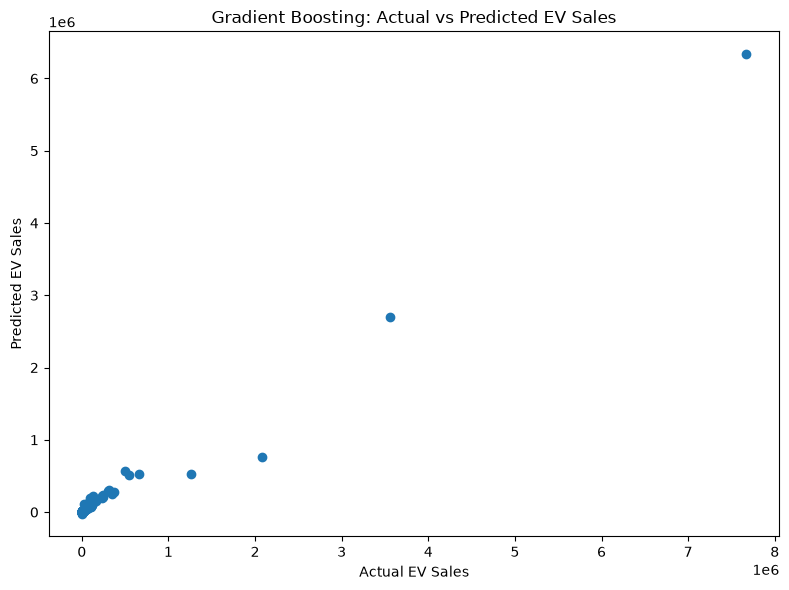

In [103]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_predictions
)

plt.xlabel(
    "Actual EV Sales"
)

plt.ylabel(
    "Predicted EV Sales"
)

plt.title(
    "Gradient Boosting: Actual vs Predicted EV Sales"
)

plt.tight_layout()

plt.show()

## Feature Importance Analysis
I analysed feature importance using my final  Gradient Boosting model. The model assigned an importance score to every feature, and I sorted these scores to identify the top 15 features that contributed most to predicting EV sales.

In [104]:
feature_importance = pd.DataFrame({

    "Feature":
        X_train.columns,

    "Importance":
        final_model.feature_importances_

})

feature_importance = feature_importance.sort_values(

    by="Importance",

    ascending=False
)

display(
    feature_importance.head(15)
)

,Feature,Importance
4,numerical__charging_stations,0.485061
3,numerical__total_vehicle_sales,0.370222
1,numerical__petrol_car_sales,0.047488
2,numerical__diesel_car_sales,0.030692
47,categorical__vehicle_segment_premium,0.015100
13,numerical__emission_regulation_score,0.013709
45,categorical__vehicle_segment_commercial,0.007993
0,numerical__year,0.007612
14,numerical__ev_growth_rate_yoy,0.004200
5,numerical__fast_chargers_share,0.003575


## Top 10 Feature Importance Visualization

I visualized the top 10 important features from my final Gradient Boosting model using a horizontal bar chart. The length of each bar represents the feature's relative importance, allowing me to easily identify which variables contributed most to predicting EV sales.

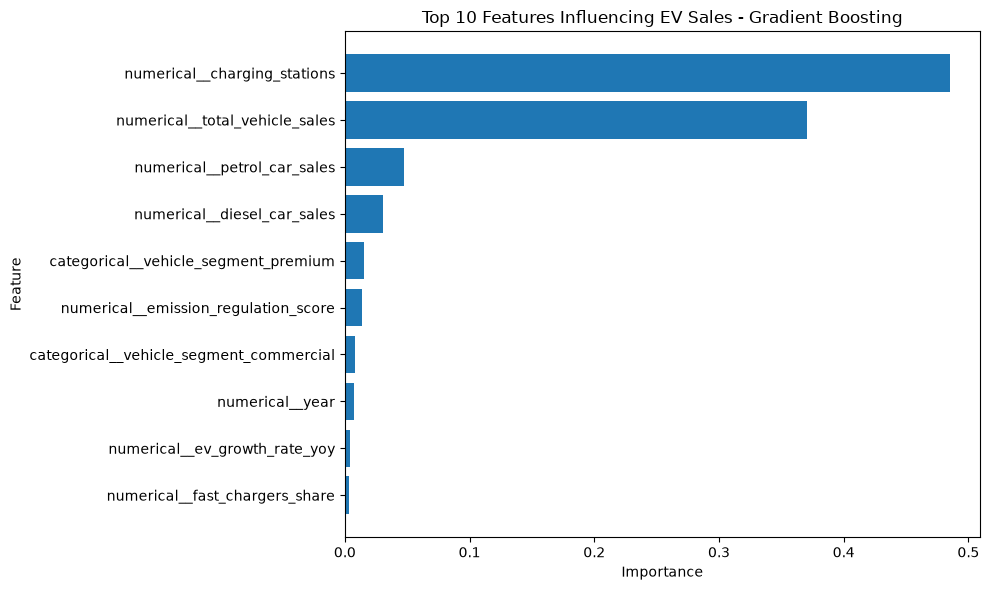

In [105]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(

    top_features["Feature"],

    top_features["Importance"]

)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top 10 Features Influencing EV Sales - Gradient Boosting"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

## Saving the Final Model

After completing model tuning and final evaluation, I saved the optimized Gradient Boosting model as a pickle file using Joblib. This allows the trained model to be reused for future predictions without retraining it.

In [106]:
joblib.dump(
    final_model,
    "ev_sales_best_model.pkl"
)

print(
    "Final model saved successfully!"
)

print(
    "File: ev_sales_best_model.pkl"
)

Final model saved successfully!
File: ev_sales_best_model.pkl


## Saving the Prediction Results
I saved the final prediction results as a CSV file containing the actual EV sales, predicted EV sales, and their differences. This file can be used later for analysis and visualization.

In [107]:
final_comparison.to_csv(
    "ev_sales_predictions.csv",
    index=False
)

print(
    "Prediction file saved successfully!"
)

print(
    "File: ev_sales_predictions.csv"
)

Prediction file saved successfully!
File: ev_sales_predictions.csv


## Saving Feature Importance
I saved the feature importance results into a CSV file. This file shows which features contributed most to the EV sales predictions and can be used for further analysis and Power BI visualization.


In [108]:
feature_importance.to_csv(

    "ev_sales_feature_importance.csv",

    index=False
)

print(
    "Feature importance saved successfully!"
)

Feature importance saved successfully!


## Final Model Summary and Interpretation
In the final stage, I summarized my Gradient Boosting model using MAE, RMSE, and R² Score. I interpreted the R² Score to understand the model's predictive performance and displayed the top five important features to understand which variables contributed most to the EV sales predictions.


In [109]:
print(
    f"\nTarget Variable: EV Sales (ev_sales)"
)

print(
    f"\nFinal Model: Gradient Boosting Regressor"
)
print(
    f"\nFinal MAE: {final_mae:.2f}"
)

print(
    f"Final RMSE: {final_rmse:.2f}"
)

print(
    f"Final R² Score: {final_r2:.4f}"
)

print("\nModel Interpretation:")

if final_r2 >= 0.80:

    print(
        "The model shows strong predictive performance "
        "for EV sales."
    )

elif final_r2 >= 0.60:

    print(
        "The model shows reasonably good predictive "
        "performance for EV sales."
    )

else:

    print(
        "The model has moderate predictive performance "
        "and may require further improvement."
    )

print(
    "\nThe model can be used to estimate EV sales "
    "from the available market, economic, infrastructure "
    "and vehicle-related features."
)

print(
    "\nTop 5 important features:"
)

display(
    feature_importance.head(5)
)


Target Variable: EV Sales (ev_sales)

Final Model: Gradient Boosting Regressor

Final MAE: 24342.29
Final RMSE: 142712.67
Final R² Score: 0.9368

Model Interpretation:
The model shows strong predictive performance for EV sales.

The model can be used to estimate EV sales from the available market, economic, infrastructure and vehicle-related features.

Top 5 important features:


,Feature,Importance
4,numerical__charging_stations,0.485061
3,numerical__total_vehicle_sales,0.370222
1,numerical__petrol_car_sales,0.047488
2,numerical__diesel_car_sales,0.030692
47,categorical__vehicle_segment_premium,0.015100


## Model Building Conclusion
The Model Building stage successfully developed and evaluated machine-learning models for predicting EV sales (ev_sales). The processed training and testing datasets were used to train multiple regression algorithms, including Linear Regression, Decision Tree, Random Forest, and Gradient Boosting.

The models were evaluated using MAE, MSE, RMSE, and R² Score, allowing their predictive performance to be compared objectively. The Random Forest model was further optimized using GridSearchCV and 5-fold cross-validation, where different hyperparameter combinations were tested to improve its performance. Gradient Boosting hyperparameter tuning was also performed as part of the model optimization process.

After model selection and tuning, the final model was evaluated on the unseen test dataset. Actual-versus-predicted comparisons and visualizations were created to understand prediction accuracy, while feature-importance analysis was used to identify the variables contributing most to EV sales predictions.

Finally, the trained model, prediction results, feature names, model metrics, and feature-importance results were saved as reusable artifacts. Overall, the Model Building stage established a complete and reusable machine-learning pipeline for EV sales prediction, providing the foundation for the next stages of model deployment, prediction, and Power BI visualization.